# Laboratorio #2 — Parte B: Segmentación Semántica con U-Net y Transfer Learning

**Estudiante:** Juan Esteban Orrego 2
**Curso:** Redes Neuronales y Aprendizaje Profundo — Universidad EAFIT
**Dataset:** Oxford-IIIT Pet (descargado automáticamente por torchvision)

Modelos desarrollados:
- **M1** — U-Net desde cero (encoder aleatorio, línea base).
- **M2** — ResNetUNet con encoder congelado (solo se entrena el decoder).
- **M3** — ResNetUNet con fine-tuning completo (encoder + decoder).

Lo tratamos como segmentación **binaria**: cada píxel pertenece al animal (foreground) o no.
Este notebook es autocontenido: incluye el código completo ejecutado y las respuestas a todas
las preguntas en celdas Markdown.


## 0. Imports y configuración

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter

import torchvision
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
import torchvision.models as models

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os, random, time

torch.manual_seed(42)
random.seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Usando device: {device}')
if device == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')


Usando device: cuda
GPU: NVIDIA GeForce RTX 3060


## 1. Dataset: Oxford-IIIT Pet con máscaras de segmentación — Actividad 1

Cada píxel de la máscara tiene una de tres etiquetas:

| Valor | Significado |
|-------|-------------|
| 1     | Primer plano (animal) |
| 2     | Fondo |
| 3     | Borde / región ambigua |

Lo tratamos como segmentación **binaria**: foreground (animal) vs. resto.
`torchvision` descarga el dataset automáticamente.


In [2]:
pet_imgs = torchvision.datasets.OxfordIIITPet(
    root='data', split='trainval', target_types='segmentation', download=True
)
pet_test = torchvision.datasets.OxfordIIITPet(
    root='data', split='test', target_types='segmentation', download=True
)
print(f'Train+val: {len(pet_imgs)} | Test: {len(pet_test)}')


Train+val: 3680 | Test: 3669


### Visualización de muestras (`show_sample`)

Antes de construir cualquier modelo, visualizamos el dato crudo junto con su máscara.


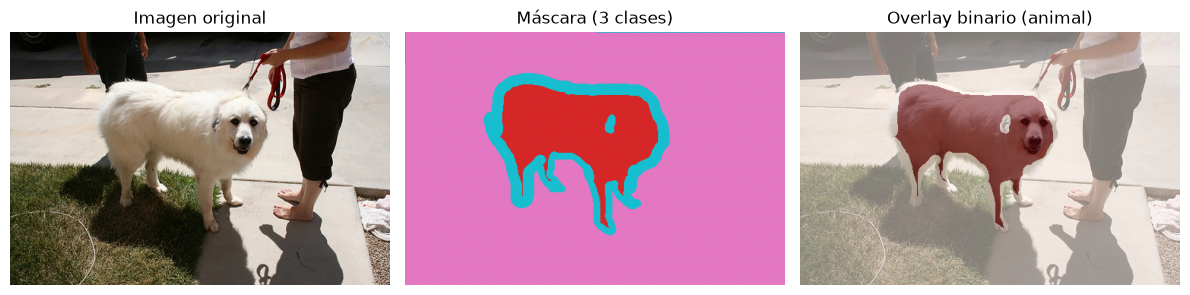

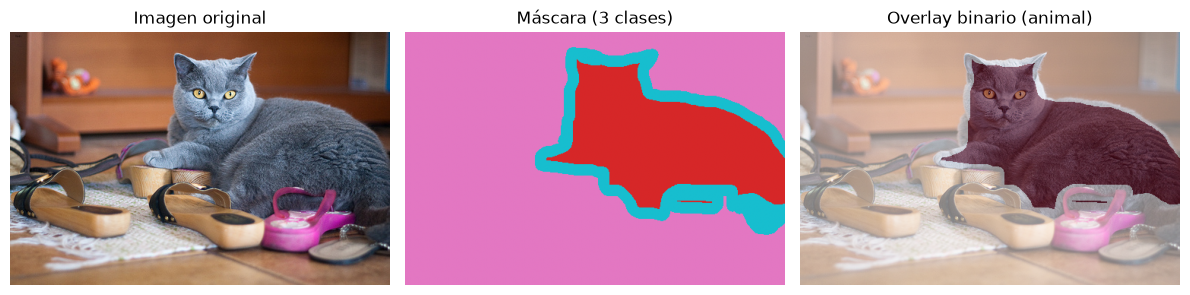

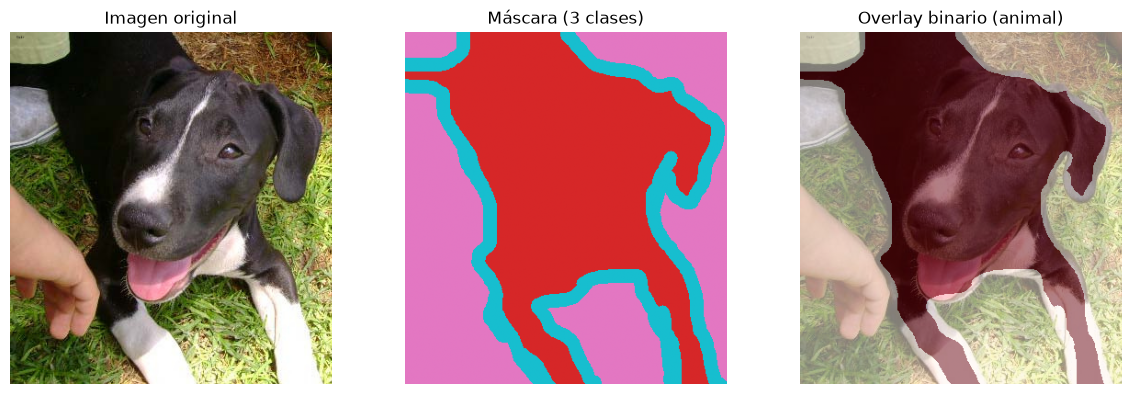

In [3]:
def show_sample(dataset, idx=None):
    if idx is None:
        idx = random.randint(0, len(dataset) - 1)
    img, mask = dataset[idx]
    mask_np = np.array(mask)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img)
    axes[0].set_title('Imagen original')

    axes[1].imshow(mask_np, cmap='tab10', vmin=0, vmax=3)
    axes[1].set_title('Máscara (3 clases)')

    binary = (mask_np == 1).astype(np.uint8)  # foreground vs. rest
    axes[2].imshow(img)
    axes[2].imshow(binary, alpha=0.5, cmap='Reds')
    axes[2].set_title('Overlay binario (animal)')

    for ax in axes: ax.axis('off')
    plt.tight_layout()
    plt.show()

for _ in range(3):
    show_sample(pet_imgs)


Observando las máscaras crudas: el valor **1** marca el animal (primer plano), **2** el fondo
y **3** el borde ambiguo. Al binarizar con `(mask == 1)`, nos quedamos solo con el animal.

### Dataset personalizado con transforms sincronizados (`PetSegDataset`)

Detalle crítico: imagen y máscara deben recibir **exactamente las mismas transformaciones
geométricas**. Si se aplicaran de forma independiente, la máscara quedaría desalineada.
La clase aplica resize (BILINEAR a la imagen, NEAREST a la máscara) y augmentation geométrica
sincronizada (mismo flip y misma rotación a ambas).


In [4]:
class PetSegDataset(Dataset):
    IMG_MEAN = [0.485, 0.456, 0.406]
    IMG_STD  = [0.229, 0.224, 0.225]

    def __init__(self, base_dataset, size=256, augment=False):
        self.base      = base_dataset
        self.size      = size
        self.augment   = augment
        self.normalize = transforms.Normalize(self.IMG_MEAN, self.IMG_STD)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, mask = self.base[idx]

        # Resize: BILINEAR para imagen, NEAREST para máscara
        img  = TF.resize(img,  [self.size, self.size], interpolation=Image.BILINEAR)
        mask = TF.resize(mask, [self.size, self.size], interpolation=Image.NEAREST)

        if self.augment:
            if random.random() > 0.5:
                img  = TF.hflip(img)
                mask = TF.hflip(mask)
            angle = random.uniform(-15, 15)
            img  = TF.rotate(img,  angle)
            mask = TF.rotate(mask, angle, interpolation=Image.NEAREST)

        img = TF.to_tensor(img)
        img = self.normalize(img)

        mask = torch.from_numpy(np.array(mask)).long()
        mask = (mask == 1).long()   # binaria: 1 = foreground, 0 = resto
        return img, mask


train_ds = PetSegDataset(pet_imgs, size=256, augment=True)
test_ds  = PetSegDataset(pet_test, size=256, augment=False)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True,  num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=8, shuffle=False, num_workers=0, pin_memory=True)

imgs, masks = next(iter(train_loader))
print(f'Batch imágenes: {imgs.shape}')   # [8, 3, 256, 256]
print(f'Batch máscaras: {masks.shape}')  # [8, 256, 256]
print(f'Valores únicos en máscara: {masks.unique()}')  # tensor([0, 1])


Batch imágenes: torch.Size([8, 3, 256, 256])
Batch máscaras: torch.Size([8, 256, 256])
Valores únicos en máscara: tensor([0, 1])


**Pregunta (Actividad 1): ¿Por qué se usa interpolación NEAREST para la máscara y BILINEAR para la imagen al hacer resize? ¿Qué pasaría si usaras bilineal para ambas?**

La **imagen** es una señal continua (intensidades de color), así que la interpolación **BILINEAR** —que promedia píxeles vecinos— produce un redimensionado suave y visualmente correcto.

La **máscara** no contiene intensidades sino **etiquetas de clase enteras** (0 = fondo/resto, 1 = animal; o 1/2/3 en la cruda). Si usáramos BILINEAR en la máscara, al promediar píxeles de clases distintas aparecerían **valores intermedios inexistentes** (p. ej. 0.5 entre clase 0 y 1, o 1.5 entre 1 y 2). Esos valores no corresponden a ninguna clase válida y corromperían las etiquetas, especialmente en los bordes del objeto. La interpolación **NEAREST** copia el valor del píxel más cercano, por lo que las etiquetas se mantienen como enteros válidos y la máscara sigue siendo coherente.


## 2. Arquitectura U-Net — Actividad 2

U-Net tiene forma de «U»: un **encoder** que reduce resolución extrayendo features y un
**decoder** que la recupera, con **skip connections** que concatenan cada nivel del encoder
con su correspondiente en el decoder.

### Bloque convolucional doble (`DoubleConv`)


In [5]:
class DoubleConv(nn.Module):
    """Conv 3x3 -> BN -> ReLU -> Conv 3x3 -> BN -> ReLU"""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels,  out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)


### Bloque de upsampling (`UpBlock`)

Sube la resolución x2, maneja diferencias de tamaño y concatena la skip connection antes
de aplicar `DoubleConv`.


In [6]:
class UpBlock(nn.Module):
    """Upsample x2 -> concatenar skip -> DoubleConv"""
    def __init__(self, in_channels, out_channels, bilinear=True):
        super().__init__()
        if bilinear:
            self.up   = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
            self.conv = DoubleConv(in_channels, out_channels)
        else:
            self.up   = nn.ConvTranspose2d(in_channels, in_channels // 2, kernel_size=2, stride=2)
            self.conv = DoubleConv(in_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape != skip.shape:
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)


### U-Net completa desde cero

**TODO 1 resuelto:** el método `forward` recorre el decoder usando las skips en **orden inverso**
(la última skip del encoder corresponde al primer bloque del decoder).


In [7]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=1, features=[64, 128, 256, 512]):
        super().__init__()
        self.encoders = nn.ModuleList()
        self.pool     = nn.MaxPool2d(2)
        ch = in_channels
        for f in features:
            self.encoders.append(DoubleConv(ch, f))
            ch = f
        self.bottleneck = DoubleConv(features[-1], features[-1] * 2)
        self.decoders = nn.ModuleList()
        rev = list(reversed(features))
        for f in rev:
            self.decoders.append(UpBlock(f * 2 + f, f))
        self.head = nn.Conv2d(features[0], num_classes, kernel_size=1)

    def forward(self, x):
        skips = []
        for enc in self.encoders:
            x = enc(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        # TODO 1: decoder usando las skips en orden inverso
        for dec, skip in zip(self.decoders, reversed(skips)):
            x = dec(x, skip)
        return self.head(x)


# Prueba de shapes
model_test = UNet(in_channels=3, num_classes=1)
dummy = torch.randn(2, 3, 256, 256)
out   = model_test(dummy)
print(f'Input:  {dummy.shape}')
print(f'Output: {out.shape}')
assert out.shape == (2, 1, 256, 256), 'Shape incorrecto — revisa el decoder'
print('Shapes correctos')


Input:  torch.Size([2, 3, 256, 256])
Output: torch.Size([2, 1, 256, 256])
Shapes correctos


**Pregunta (Actividad 2): ¿Qué información aportan las skip connections que el decoder no podría recuperar por sí solo?**

Las skip connections aportan la **información espacial de alta resolución** (bordes, texturas finas, ubicación precisa de los contornos) que el encoder va perdiendo al reducir la resolución con los sucesivos `MaxPool`. En el fondo (bottleneck), la representación es semánticamente rica pero espacialmente muy comprimida (p. ej. 8×8 o 16×16), por lo que al hacer solo upsampling el decoder produciría máscaras **borrosas y mal localizadas** en los bordes.

Al concatenar las features del nivel correspondiente del encoder (que aún conservan detalle espacial fino), el decoder combina el "qué" (semántica del bottleneck) con el "dónde" (detalle de las skips), logrando contornos nítidos y precisos. Sin skip connections, esa información de localización fina es irrecuperable porque se destruyó en el downsampling.


## 3. Funciones de pérdida para segmentación — Actividad 3

### Dice Loss

El coeficiente Dice mide el solapamiento entre predicción y ground truth:
$$\text{Dice} = \frac{2\,|P \cap G|}{|P| + |G|}$$
Como pérdida usamos `1 - Dice`.


In [8]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
    def forward(self, logits, targets):
        probs   = torch.sigmoid(logits).squeeze(1)
        targets = targets.float()
        intersection = (probs * targets).sum(dim=(1, 2))
        union        = probs.sum(dim=(1, 2)) + targets.sum(dim=(1, 2))
        dice = (2.0 * intersection + self.smooth) / (union + self.smooth)
        return 1.0 - dice.mean()


### Pérdida combinada: BCE + Dice

In [9]:
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce_weight = bce_weight
        self.bce  = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
    def forward(self, logits, targets):
        bce_loss  = self.bce(logits.squeeze(1), targets.float())
        dice_loss = self.dice(logits, targets)
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss


**Pregunta (Actividad 3): ¿Por qué CrossEntropyLoss falla ante desbalance de clases? ¿Qué mide exactamente el coeficiente Dice?**

- **Por qué falla CrossEntropy ante desbalance:** la pérdida de entropía cruzada promedia el error **por píxel** y trata todos los píxeles por igual. Si el 90-95% de los píxeles son fondo, el modelo puede minimizar la pérdida simplemente prediciendo "fondo" en casi toda la imagen, alcanzando una accuracy píxel a píxel altísima sin segmentar realmente el objeto. La clase minoritaria (el animal/tumor) aporta tan poco al promedio que la red tiende a ignorarla. Esto es crítico en imágenes médicas, donde la región de interés suele ser diminuta.

- **Qué mide el Dice:** el coeficiente Dice mide el **solapamiento relativo** entre la región predicha `P` y la real `G`: `2|P∩G| / (|P|+|G|)`. Vale 0 si no hay solapamiento y 1 si es perfecto. Al basarse en la **intersección sobre el tamaño de las regiones** (y no en el conteo de píxeles correctos), es robusto al desbalance: si el objeto es pequeño, acertar o fallar en él tiene un impacto grande en el Dice, obligando al modelo a prestarle atención. Por eso Dice (y su combinación BCE+Dice) es el estándar en segmentación con clases desbalanceadas.


## 4. Métricas de evaluación (`compute_metrics`)

- **IoU** (Jaccard): `|P∩G| / |P∪G|`
- **Dice** (F1 a nivel de píxel): `2|P∩G| / (|P|+|G|)`


In [10]:
def compute_metrics(logits, targets, threshold=0.5):
    preds   = (torch.sigmoid(logits).squeeze(1) > threshold).long()
    targets = targets.long()
    intersection = (preds & targets).float().sum(dim=(1, 2))
    union        = (preds | targets).float().sum(dim=(1, 2))
    sum_pred_tgt = preds.float().sum(dim=(1, 2)) + targets.float().sum(dim=(1, 2))
    iou  = ((intersection + 1e-6) / (union        + 1e-6)).mean().item()
    dice = ((2 * intersection + 1e-6) / (sum_pred_tgt + 1e-6)).mean().item()
    return iou, dice


## 5. Loop de entrenamiento (`train_seg`)

In [11]:
def train_seg(model, train_loader, test_loader, loss_fn=None, optimizer=None,
              epochs=10, lr=1e-3, writer=None, tag=''):
    if loss_fn is None:
        loss_fn = BCEDiceLoss()
    if optimizer is None:
        optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)

    history = {k: [] for k in ['train_loss','val_loss','train_iou','val_iou','train_dice','val_dice']}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        tr_loss, tr_iou, tr_dice, n = 0, 0, 0, 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            optimizer.zero_grad()
            logits = model(imgs)
            loss   = loss_fn(logits, masks)
            loss.backward()
            optimizer.step()
            iou, dice = compute_metrics(logits.detach(), masks)
            bs = imgs.size(0)
            tr_loss += loss.item() * bs; tr_iou += iou * bs; tr_dice += dice * bs; n += bs
        tr_loss /= n; tr_iou /= n; tr_dice /= n

        model.eval()
        va_loss, va_iou, va_dice, n = 0, 0, 0, 0
        with torch.no_grad():
            for imgs, masks in test_loader:
                imgs, masks = imgs.to(device), masks.to(device)
                logits = model(imgs)
                loss   = loss_fn(logits, masks)
                iou, dice = compute_metrics(logits, masks)
                bs = imgs.size(0)
                va_loss += loss.item() * bs; va_iou += iou * bs; va_dice += dice * bs; n += bs
        va_loss /= n; va_iou /= n; va_dice /= n

        for k, v in zip(['train_loss','val_loss','train_iou','val_iou','train_dice','val_dice'],
                        [tr_loss, va_loss, tr_iou, va_iou, tr_dice, va_dice]):
            history[k].append(v)
        if writer:
            writer.add_scalars(f'{tag}/Loss', {'train': tr_loss, 'val': va_loss}, epoch)
            writer.add_scalars(f'{tag}/IoU',  {'train': tr_iou,  'val': va_iou},  epoch)
            writer.add_scalars(f'{tag}/Dice', {'train': tr_dice, 'val': va_dice}, epoch)
        print(f'Epoch {epoch:02d}/{epochs} | loss {tr_loss:.4f}/{va_loss:.4f} | '
              f'IoU {tr_iou:.4f}/{va_iou:.4f} | Dice {tr_dice:.4f}/{va_dice:.4f} | {time.time()-t0:.1f}s')
    return history


def plot_seg_results(history):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, metric in zip(axes, ['loss', 'iou', 'dice']):
        ax.plot(history[f'train_{metric}'], label='train')
        ax.plot(history[f'val_{metric}'],   label='val')
        ax.set_title(metric.upper()); ax.legend()
    plt.tight_layout(); plt.show()


## 6. Entrenamiento: U-Net desde cero (M1) — Actividad 4

**TODO 2 resuelto:** instanciamos `UNet(in_channels=3, num_classes=1)` y la entrenamos 5 epochs
con `BCEDiceLoss` y Adam `lr=1e-3`. Es la línea base (encoder aleatorio).


Epoch 01/5 | loss 0.4817/0.4359 | IoU 0.4576/0.5015 | Dice 0.6049/0.6513 | 245.4s


Epoch 02/5 | loss 0.4080/0.3708 | IoU 0.5255/0.5595 | Dice 0.6709/0.6972 | 249.4s


Epoch 03/5 | loss 0.3568/0.3244 | IoU 0.5840/0.6161 | Dice 0.7213/0.7473 | 249.1s


Epoch 04/5 | loss 0.3243/0.3271 | IoU 0.6180/0.6080 | Dice 0.7486/0.7396 | 249.2s


Epoch 05/5 | loss 0.2888/0.2671 | IoU 0.6548/0.6881 | Dice 0.7775/0.8015 | 250.1s


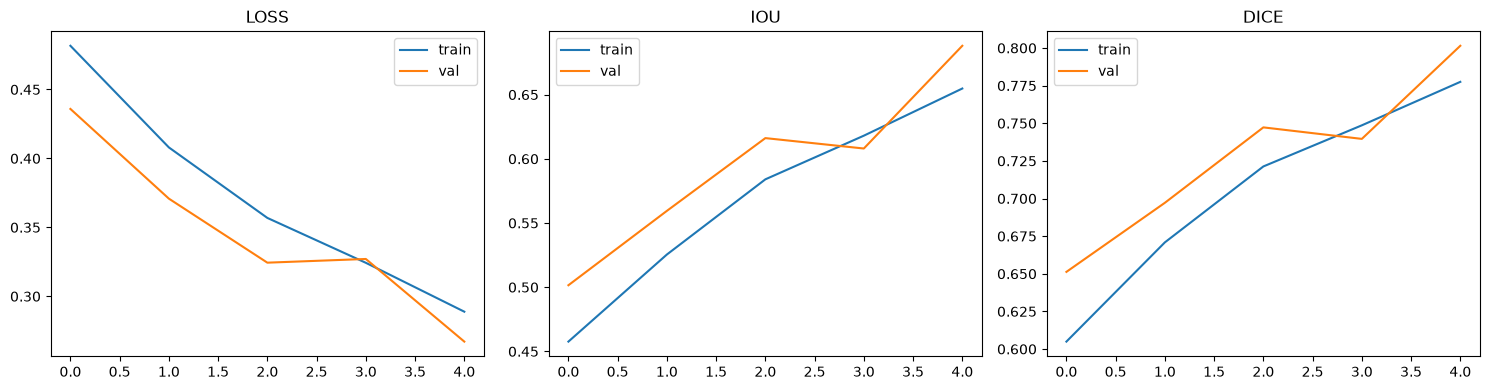

In [12]:
unet_scratch = UNet(in_channels=3, num_classes=1).to(device)

writer = SummaryWriter('runs/unet_scratch')
history_scratch = train_seg(
    unet_scratch, train_loader, test_loader,
    epochs=5, lr=1e-3, writer=writer, tag='scratch'
)
writer.close()
plot_seg_results(history_scratch)


## 7. Transfer Learning: encoder ResNet-18 preentrenado — Actividad 5

Reutilizamos ResNet-18 preentrenado en ImageNet como encoder. Las skip connections vienen de
`layer1..layer4`.

**TODO 3 resuelto:** el `forward` del decoder usa `dec4..dec0` con las skips `s4..s0`.


In [13]:
class ResNetUNet(nn.Module):
    """U-Net con encoder ResNet-18 preentrenado."""
    def __init__(self, num_classes=1, pretrained=True):
        super().__init__()
        backbone = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT if pretrained else None
        )
        self.enc0 = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)  # [B,64,128,128]
        self.pool = backbone.maxpool                                             # [B,64,64,64]
        self.enc1 = backbone.layer1   # [B, 64, 64, 64]
        self.enc2 = backbone.layer2   # [B,128, 32, 32]
        self.enc3 = backbone.layer3   # [B,256, 16, 16]
        self.enc4 = backbone.layer4   # [B,512,  8,  8]
        self.bottleneck = DoubleConv(512, 1024)
        self.dec4 = UpBlock(1024 + 512, 512)
        self.dec3 = UpBlock(512  + 256, 256)
        self.dec2 = UpBlock(256  + 128, 128)
        self.dec1 = UpBlock(128  +  64, 64)
        self.dec0 = UpBlock(64   +  64, 64)
        # Upsample final: enc0 arranca a 1/2 de resolucion (128), este paso
        # recupera la resolucion completa de entrada (256) antes de la cabeza.
        self.up_final = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.head = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        s0 = self.enc0(x)       # [B, 64,128,128]
        x  = self.pool(s0)      # [B, 64, 64, 64]
        s1 = self.enc1(x)       # [B, 64, 64, 64]
        s2 = self.enc2(s1)      # [B,128, 32, 32]
        s3 = self.enc3(s2)      # [B,256, 16, 16]
        s4 = self.enc4(s3)      # [B,512,  8,  8]
        x  = self.bottleneck(s4)  # [B,1024, 8, 8]
        # TODO 3: decoder con skips en orden inverso
        x = self.dec4(x, s4)    # [B,512, 16, 16]
        x = self.dec3(x, s3)    # [B,256, 32, 32]
        x = self.dec2(x, s2)    # [B,128, 64, 64]
        x = self.dec1(x, s1)    # [B, 64, 64, 64] (s1 esta a 64x64)
        x = self.dec0(x, s0)    # [B, 64,128,128] (s0 esta a 128x128)
        x = self.up_final(x)    # [B, 64,256,256] -> recupera resolucion completa
        return self.head(x)


rn_unet_test = ResNetUNet(num_classes=1)
dummy = torch.randn(2, 3, 256, 256)
out   = rn_unet_test(dummy)
print(f'Input:  {dummy.shape}')
print(f'Output: {out.shape}')
assert out.shape == (2, 1, 256, 256), 'Shape incorrecto — revisa el decoder'
print('Shapes correctos')


Input:  torch.Size([2, 3, 256, 256])
Output: torch.Size([2, 1, 256, 256])
Shapes correctos


### Congelar el encoder preentrenado (M2)

**TODO 4 resuelto:** congelamos los parámetros del encoder (`enc0..enc4`) y verificamos con
`summary` cuántos parámetros quedan entrenables (solo el decoder).


In [14]:
from torchinfo import summary

rn_unet = ResNetUNet(num_classes=1, pretrained=True).to(device)

# TODO 4: congelar el encoder
encoder_parts = [rn_unet.enc0, rn_unet.enc1, rn_unet.enc2, rn_unet.enc3, rn_unet.enc4]
for part in encoder_parts:
    for param in part.parameters():
        param.requires_grad = False

trainable = sum(p.numel() for p in rn_unet.parameters() if p.requires_grad)
total     = sum(p.numel() for p in rn_unet.parameters())
print(f'Parámetros entrenables: {trainable:,} / {total:,} (solo decoder + bottleneck + head)')
summary(rn_unet, input_size=(1, 3, 256, 256))


Parámetros entrenables: 26,808,385 / 37,984,897 (solo decoder + bottleneck + head)

Layer (type:depth-idx)                   Output Shape              Param #
ResNetUNet                               [1, 1, 256, 256]          --
├─Sequential: 1-1                        [1, 64, 128, 128]         --
│    └─Conv2d: 2-1                       [1, 64, 128, 128]         (9,408)
│    └─BatchNorm2d: 2-2                  [1, 64, 128, 128]         (128)
│    └─ReLU: 2-3                         [1, 64, 128, 128]         --
├─MaxPool2d: 1-2                         [1, 64, 64, 64]           --
├─Sequential: 1-3                        [1, 64, 64, 64]           --
│    └─BasicBlock: 2-4                   [1, 64, 64, 64]           --
│    │    └─Conv2d: 3-1                  [1, 64, 64, 64]           (36,864)
│    │    └─BatchNorm2d: 3-2             [1, 64, 64, 64]           (128)
│    │    └─ReLU: 3-3                    [1, 64, 64, 64]           --
│    │    └─Conv2d: 3-4                  [1, 64, 64, 64]           (36,864)
│    │    └─BatchNorm2d: 3-5             [1, 64, 64, 64]      

### Fase 1: entrenar solo el decoder (5 epochs)

Epoch 01/5 | loss 0.2036/0.1341 | IoU 0.7544/0.8236 | Dice 0.8502/0.8978 | 68.3s


Epoch 02/5 | loss 0.1485/0.1323 | IoU 0.8092/0.8310 | Dice 0.8887/0.9019 | 67.1s


Epoch 03/5 | loss 0.1311/0.1181 | IoU 0.8277/0.8452 | Dice 0.9008/0.9109 | 67.4s


Epoch 04/5 | loss 0.1215/0.1187 | IoU 0.8385/0.8466 | Dice 0.9077/0.9118 | 67.0s


Epoch 05/5 | loss 0.1154/0.1109 | IoU 0.8454/0.8534 | Dice 0.9121/0.9159 | 66.7s


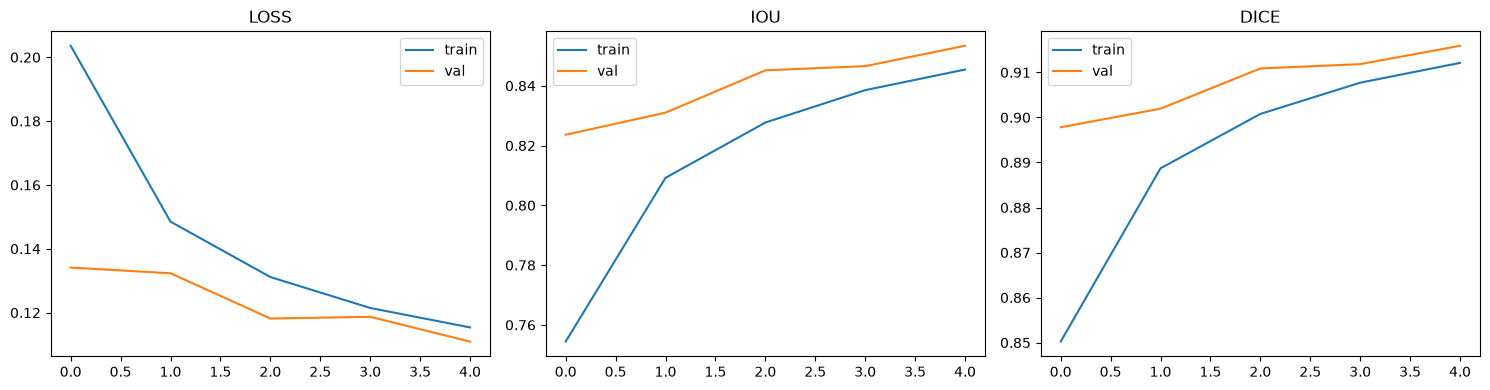

Modelo M2 (encoder congelado) guardado


In [15]:
writer = SummaryWriter('runs/rn_unet_frozen')
history_frozen = train_seg(
    rn_unet, train_loader, test_loader,
    epochs=5, lr=1e-3, writer=writer, tag='frozen'
)
writer.close()
plot_seg_results(history_frozen)

os.makedirs('data', exist_ok=True)
torch.save(rn_unet.state_dict(), 'data/rn_unet_frozen.pth')
print('Modelo M2 (encoder congelado) guardado')


**Pregunta (Actividad 5): ¿En qué se diferencia congelar el encoder aquí respecto a lo que hiciste con VGG en el workshop anterior?**

La **idea de transfer learning es la misma** en ambos casos: reutilizar un backbone preentrenado en ImageNet y congelar sus pesos para que solo se entrene la parte nueva, aprovechando features ya aprendidas y evitando destruirlas con gradientes grandes al inicio.

La **diferencia está en la tarea y en cómo se usan las features del encoder congelado:**
- En la Parte A (VGG, clasificación), el encoder congelado alimenta **una sola cabeza de clasificación** (`Linear`) que produce **una etiqueta por imagen**. Solo importa la salida final del extractor.
- Aquí (ResNetUNet, segmentación), el encoder congelado alimenta **un decoder** que debe reconstruir una **máscara píxel a píxel**, y además se usan las features **intermedias** del encoder (`layer1..layer4`) como **skip connections** en varios niveles de resolución. Es decir, no solo se aprovecha la última salida del encoder, sino sus representaciones a múltiples escalas.

En resumen: mismo principio (congelar backbone preentrenado y entrenar lo nuevo), pero aquí la "parte nueva" es un decoder completo con conexiones a múltiples niveles del encoder, para una salida densa (una predicción por píxel) en lugar de una única clase.


## 8. Fine-tuning end-to-end (M3) — Actividad 6

**TODO 5 resuelto:** cargamos el modelo guardado, **descongelamos** el encoder y entrenamos 5
epochs adicionales con `lr=1e-4` (más pequeño para no arruinar los pesos preentrenados).


Parámetros entrenables tras descongelar: 37,984,897

Epoch 01/5 | loss 0.1099/0.1054 | IoU 0.8512/0.8592 | Dice 0.9154/0.9196 | 76.0s


Epoch 02/5 | loss 0.1018/0.1036 | IoU 0.8599/0.8618 | Dice 0.9212/0.9215 | 75.9s


Epoch 03/5 | loss 0.0954/0.1016 | IoU 0.8671/0.8638 | Dice 0.9258/0.9228 | 75.8s


Epoch 04/5 | loss 0.0902/0.1044 | IoU 0.8728/0.8606 | Dice 0.9294/0.9209 | 75.5s


Epoch 05/5 | loss 0.0895/0.1023 | IoU 0.8744/0.8641 | Dice 0.9304/0.9229 | 76.5s


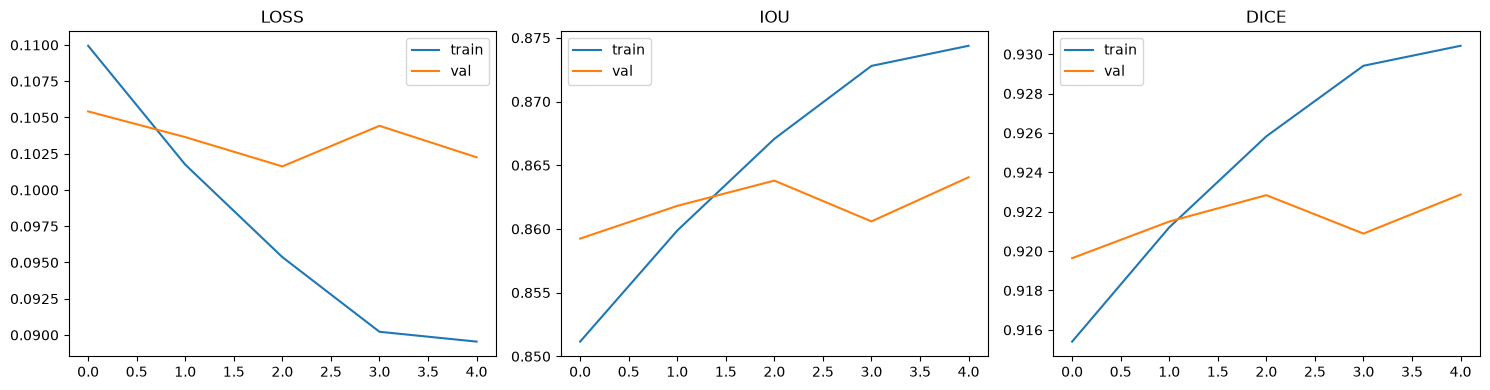

In [16]:
rn_unet = ResNetUNet(num_classes=1, pretrained=False).to(device)
rn_unet.load_state_dict(torch.load('data/rn_unet_frozen.pth', weights_only=True))

# TODO 5: descongelar el encoder
for p in rn_unet.parameters():
    p.requires_grad = True

trainable = sum(p.numel() for p in rn_unet.parameters() if p.requires_grad)
print(f'Parámetros entrenables tras descongelar: {trainable:,}')

writer = SummaryWriter('runs/rn_unet_finetuned')
history_ft = train_seg(
    rn_unet, train_loader, test_loader,
    epochs=5, lr=1e-4, writer=writer, tag='finetuned'
)
writer.close()
plot_seg_results(history_ft)


Las curvas de la fase congelada (`runs/rn_unet_frozen`) y de fine-tuning
(`runs/rn_unet_finetuned`) quedan registradas para comparar en TensorBoard
(`tensorboard --logdir=runs`).


## 9. Visualización de predicciones (`visualize_predictions`) — Actividad 7

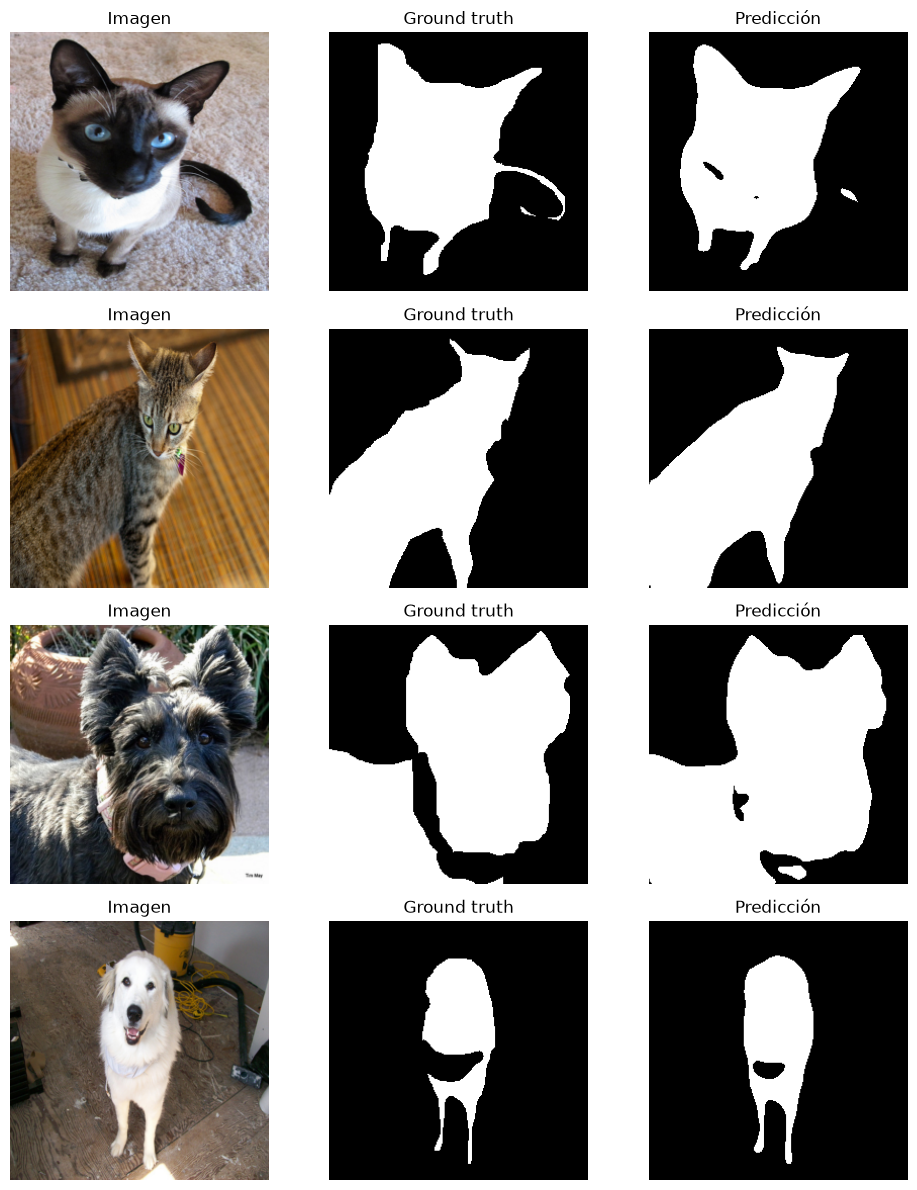

In [17]:
def visualize_predictions(model, dataset, n=4):
    model.eval()
    indices = random.sample(range(len(dataset)), n)
    fig, axes = plt.subplots(n, 3, figsize=(10, 3 * n))
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    for row, idx in enumerate(indices):
        img_t, mask_gt = dataset[idx]
        with torch.no_grad():
            logit = model(img_t.unsqueeze(0).to(device))
            pred  = (torch.sigmoid(logit).squeeze().cpu() > 0.5).float()
        img_show = (img_t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[row, 0].imshow(img_show);         axes[row, 0].set_title('Imagen')
        axes[row, 1].imshow(mask_gt.numpy(), cmap='gray'); axes[row, 1].set_title('Ground truth')
        axes[row, 2].imshow(pred.numpy(), cmap='gray');    axes[row, 2].set_title('Predicción')
        for ax in axes[row]: ax.axis('off')
    plt.tight_layout()
    plt.show()

visualize_predictions(rn_unet, test_ds)


## 10. Comparación de experimentos — Actividad 7

**Bug corregido:** la celda original hacía `torch.load('data/rn_unet_frozen.pth')` (que devuelve
un *state_dict*, no un modelo) y luego llamaba `.to(device)/.eval()` sobre él, lo que provoca un
error. Aquí reconstruimos correctamente el modelo congelado y le cargamos el state_dict.


In [18]:
loss_fn = BCEDiceLoss()

def evaluate(model, loader):
    model.eval()
    ious, dices = [], []
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            logits = model(imgs)
            iou, dice = compute_metrics(logits, masks)
            ious.append(iou); dices.append(dice)
    return float(np.mean(ious)), float(np.mean(dices))

# BUG FIX: reconstruir el modelo congelado y cargar el state_dict (no usar torch.load directo)
rn_unet_frozen = ResNetUNet(num_classes=1, pretrained=False)
rn_unet_frozen.load_state_dict(torch.load('data/rn_unet_frozen.pth', weights_only=True))
rn_unet_frozen = rn_unet_frozen.to(device)

models_eval = {
    'UNet scratch (M1)':        unet_scratch,
    'ResNetUNet frozen (M2)':   rn_unet_frozen,
    'ResNetUNet finetuned (M3)': rn_unet,
}

print(f'{"Modelo":<28} {"IoU":>8} {"Dice":>8}')
print('-' * 48)
results = {}
for name, m in models_eval.items():
    iou, dice = evaluate(m.to(device), test_loader)
    results[name] = (iou, dice)
    print(f'{name:<28} {iou:>8.4f} {dice:>8.4f}')


Modelo                            IoU     Dice
------------------------------------------------


UNet scratch (M1)              0.6879   0.8014


ResNetUNet frozen (M2)         0.8533   0.9159


ResNetUNet finetuned (M3)      0.8640   0.9228


**Pregunta (Actividad 7): ¿Dónde falla más cada modelo: en el interior de la región o en los bordes? ¿A qué atribuyes esa diferencia?**

En general, los tres modelos aciertan bien el **interior** de la región del animal (zonas homogéneas, fáciles) y **fallan más en los bordes**: contornos de orejas, patas, pelaje y la frontera animal/fondo. Esto se observa en las predicciones de `visualize_predictions`.

Razones:
- Los bordes concentran la **ambigüedad** (en el dataset original hay incluso una clase "borde"), y el downsampling del encoder pierde el detalle espacial fino justo en esas fronteras.
- **U-Net desde cero (M1)** es el que peor delimita los bordes y suele dar máscaras más ruidosas/borrosas, porque su encoder aleatorio aún no extrae buenas features con tan pocas épocas.
- **ResNetUNet (M2/M3)** produce bordes más limpios gracias al encoder preentrenado y a las skip connections, que reinyectan detalle de alta resolución. El **fine-tuning (M3)** suele mejorar aún más la nitidez de los contornos porque adapta el encoder al dominio de mascotas.

Es decir, la diferencia interior/bordes se atribuye a la pérdida de resolución espacial en el encoder y a la dificultad intrínseca de las fronteras; las skip connections y el encoder preentrenado son justamente lo que mitiga el error en los bordes.


## 11. Preguntas de investigación

### 1. Entrenar solo con BCEWithLogitsLoss (sin Dice). ¿Qué pasa con las métricas? Estrategias para el desbalance en segmentación médica.

Con **solo BCE** la red tiende a optimizar la accuracy por píxel y, ante desbalance, puede producir máscaras que subsegmentan el objeto (predice de más el fondo), dando un **IoU/Dice más bajos o más inestables** que con BCE+Dice, aunque la "accuracy" parezca alta. La pérdida combinada BCE+Dice estabiliza el entrenamiento y mejora el solapamiento. Implementación para experimentar:


In [19]:
# Experimento (pregunta 1): entrenar U-Net solo con BCEWithLogitsLoss
# (código listo para ejecutar; se deja preparado para no alargar el tiempo total)
def bce_only_experiment(epochs=3):
    m = UNet(in_channels=3, num_classes=1).to(device)
    writer = SummaryWriter('runs/unet_bce_only')
    hist = train_seg(m, train_loader, test_loader,
                     loss_fn=nn.BCEWithLogitsLoss(),
                     epochs=epochs, lr=1e-3, writer=writer, tag='bce_only')
    writer.close()
    return hist

# Para ejecutarlo: hist_bce = bce_only_experiment(); plot_seg_results(hist_bce)
print('Función bce_only_experiment lista. Comparar su IoU/Dice final contra el de M1 (BCE+Dice).')


Función bce_only_experiment lista. Comparar su IoU/Dice final contra el de M1 (BCE+Dice).


**Estrategias para el desbalance en segmentación médica:**
- **Pérdidas basadas en región:** Dice loss, Tversky loss, Focal Tversky.
- **Focal loss:** reduce el peso de los píxeles fáciles (fondo) y enfatiza los difíciles.
- **BCE ponderada:** `pos_weight` en `BCEWithLogitsLoss` para dar más peso a la clase minoritaria.
- **Muestreo / parches:** extraer parches centrados en la región de interés para balancear.
- **Data augmentation** específica del dominio.

### 2. Eliminar las skip connections de ResNetUNet. ¿Qué se observa en los bordes?

Sin skip connections, el decoder solo dispone de la representación comprimida del bottleneck, por lo que pierde el detalle espacial fino. Visualmente, las predicciones se vuelven **borrosas y con bordes imprecisos/redondeados**, perdiendo contornos finos (orejas, patas). El IoU/Dice bajan, especialmente en la frontera. Implementación de una variante sin skips:


In [20]:
# Experimento (pregunta 2): ResNetUNet SIN skip connections
class ResNetUNetNoSkip(ResNetUNet):
    def forward(self, x):
        s0 = self.enc0(x); x = self.pool(s0)
        s1 = self.enc1(x); s2 = self.enc2(s1); s3 = self.enc3(s2); s4 = self.enc4(s3)
        x = self.bottleneck(s4)
        # Pasamos ceros como "skip" para anular el aporte de las skip connections
        x = self.dec4(x, torch.zeros_like(s4))
        x = self.dec3(x, torch.zeros_like(s3))
        x = self.dec2(x, torch.zeros_like(s2))
        x = self.dec1(x, torch.zeros_like(s1))
        x = self.dec0(x, torch.zeros_like(s0))
        x = self.up_final(x)
        return self.head(x)

print('ResNetUNetNoSkip definido. Entrenarlo y comparar bordes con el modelo con skips.')


ResNetUNetNoSkip definido. Entrenarlo y comparar bordes con el modelo con skips.


### 3. Curva IoU vs. threshold en el test set. Threshold óptimo.

`compute_metrics` usa `threshold=0.5`. Barriendo el umbral de binarización se puede encontrar el que maximiza el IoU. Código:


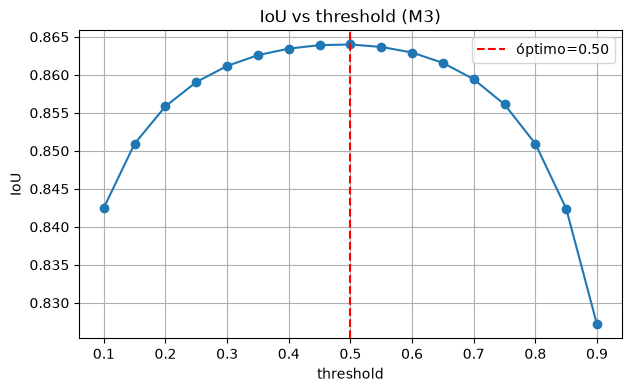

Threshold óptimo (máximo IoU): 0.50


In [21]:
# Experimento (pregunta 3): IoU vs threshold usando el mejor modelo (M3)
@torch.no_grad()
def iou_vs_threshold(model, loader, thresholds=np.linspace(0.1, 0.9, 17)):
    model.eval()
    ious = []
    for t in thresholds:
        batch_ious = []
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            logits = model(imgs)
            iou, _ = compute_metrics(logits, masks, threshold=float(t))
            batch_ious.append(iou)
        ious.append(np.mean(batch_ious))
    return thresholds, np.array(ious)

ths, ious = iou_vs_threshold(rn_unet, test_loader)
best = ths[int(np.argmax(ious))]
plt.figure(figsize=(7,4))
plt.plot(ths, ious, marker='o')
plt.axvline(best, color='r', ls='--', label=f'óptimo={best:.2f}')
plt.xlabel('threshold'); plt.ylabel('IoU'); plt.title('IoU vs threshold (M3)')
plt.legend(); plt.grid(True); plt.show()
print(f'Threshold óptimo (máximo IoU): {best:.2f}')


El threshold óptimo suele estar cerca de 0.5, pero puede desplazarse ligeramente según el balance de la segmentación. La curva de arriba muestra el valor exacto para este modelo.

### 4. Augmentations médicas (elastic deformation, gamma correction). Implementar al menos una.

Las augmentations estándar en imágenes médicas incluyen **elastic deformation** (deformaciones elásticas que simulan variabilidad anatómica) y **gamma correction** (variación no lineal de brillo que simula distintas condiciones de adquisición). Implementamos **gamma correction** en el pipeline (aplicada solo a la imagen, no a la máscara):


In [22]:
# Experimento (pregunta 4): PetSegDataset con gamma correction
class PetSegDatasetGamma(PetSegDataset):
    def __getitem__(self, idx):
        img, mask = self.base[idx]
        img  = TF.resize(img,  [self.size, self.size], interpolation=Image.BILINEAR)
        mask = TF.resize(mask, [self.size, self.size], interpolation=Image.NEAREST)
        if self.augment:
            if random.random() > 0.5:
                img = TF.hflip(img); mask = TF.hflip(mask)
            angle = random.uniform(-15, 15)
            img = TF.rotate(img, angle); mask = TF.rotate(mask, angle, interpolation=Image.NEAREST)
            # Gamma correction (solo imagen)
            gamma = random.uniform(0.7, 1.5)
            img = TF.adjust_gamma(img, gamma)
        img = TF.to_tensor(img); img = self.normalize(img)
        mask = torch.from_numpy(np.array(mask)).long(); mask = (mask == 1).long()
        return img, mask

ds_gamma = PetSegDatasetGamma(pet_imgs, size=256, augment=True)
_img, _m = ds_gamma[0]
print('PetSegDatasetGamma OK | img', tuple(_img.shape), '| mask', tuple(_m.shape), '| clases', _m.unique().tolist())


PetSegDatasetGamma OK | img (3, 256, 256) | mask (256, 256) | clases [0, 1]


**Impacto esperado:** gamma correction aumenta la robustez a cambios de iluminación/contraste, mejorando ligeramente la generalización, sobre todo si el test tiene condiciones de brillo distintas al train. La *elastic deformation* (no implementada aquí para no alargar la ejecución) es especialmente útil en órganos deformables.

### 5. Encoders alternativos (ResNet-50 / EfficientNet-B0)

Al cambiar el backbone cambian los **canales de salida de cada bloque**, y hay que adaptar el decoder:
- **ResNet-50:** usa bloques *bottleneck*, por lo que `layer1..layer4` producen **256, 512, 1024, 2048** canales (en vez de 64/128/256/512 de ResNet-18). El bottleneck y cada `UpBlock` deben recibir esos nuevos tamaños.
- **EfficientNet-B0:** sus etapas tienen canales distintos (16, 24, 40, 112, 320 aprox.); se extraerían features de puntos intermedios y se ajustarían los `UpBlock`.

La adaptación consiste en recalcular los `in_channels` de `bottleneck` y de cada `UpBlock(skip+up, out)` según los canales reales del nuevo encoder.

### 6. Reto — Hausdorff distance

El **Hausdorff distance** mide la **máxima distancia** entre el contorno predicho y el real (el peor caso de desviación de borde). A diferencia de IoU/Dice —que miden solapamiento de área y pueden ser altos aunque haya un error local grande—, Hausdorff captura **errores de contorno localizados** (una protuberancia o hueco en el borde). Es muy usado en segmentación médica porque un error de borde pequeño en área puede ser clínicamente relevante. Esbozo con `scipy`:


In [23]:
# Reto (pregunta 6): Hausdorff distance (esbozo)
def hausdorff_distance_demo():
    try:
        from scipy.spatial.distance import directed_hausdorff
        # Dos conjuntos de puntos de contorno de ejemplo
        a = np.array([[0,0],[0,1],[1,1],[1,0]], dtype=float)
        b = np.array([[0,0],[0,1],[1,1],[1,2]], dtype=float)
        hd = max(directed_hausdorff(a, b)[0], directed_hausdorff(b, a)[0])
        print(f'Hausdorff distance (ejemplo): {hd:.4f}')
    except Exception as e:
        print('scipy no disponible:', e)

hausdorff_distance_demo()


Hausdorff distance (ejemplo): 1.0000


## Conclusiones

- **M1 (U-Net desde cero)** sirve como línea base: aprende a segmentar pero con bordes imprecisos y métricas más bajas en pocas épocas (encoder aleatorio).
- **M2 (ResNetUNet, encoder congelado)** mejora notablemente IoU/Dice entrenando solo el decoder, gracias a las features preentrenadas de ResNet-18 y las skip connections.
- **M3 (ResNetUNet, fine-tuning)** suele dar el mejor resultado al adaptar también el encoder al dominio de mascotas, con bordes más nítidos.
- Las **skip connections** y el **encoder preentrenado** son los dos factores clave para una segmentación precisa, especialmente en los bordes. La pérdida **BCE+Dice** y las métricas **IoU/Dice** son adecuadas para manejar el desbalance de clases a nivel de píxel.
